# Valoración de una startup: del caso base a la distribución de valores

**Perfil:** Estrategia, innovación y venture capital  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Un flujo de caja descontado (DCF) de una empresa joven produce **un número** con aspecto de precisión. ¿Cuánto de ese número es valor terminal? ¿El caso base es el valor **esperado**? ¿Qué pasa si se combina una tasa de descuento "de venture" con una probabilidad de fracaso?

## Recorrido

1. Un modelo de DCF de 10 años con crecimiento decreciente, margen creciente y reinversión; verificación contra fórmulas cerradas.
2. **Versión 1:** caso base. **Diagnóstico:** peso del valor terminal y sensibilidades (tornado).
3. **Versión 2:** escenarios ponderados por probabilidad (incluye el fracaso).
4. **Versión 3:** Monte Carlo con incertidumbre en los supuestos; qué supuesto explica la dispersión.
5. **Doble conteo del riesgo:** tasa de descuento alta *y* probabilidad de fracaso.
6. El método de venture capital y su equivalencia con el DCF; pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy import stats

## 2. El modelo de valoración

Ingresos $R_t$ con crecimiento que **decae** geométricamente, $g_t=g_0\,\delta^{t-1}$; margen operativo que **sube linealmente** desde $m_0<0$ hasta $m_T$ en 7 años; impuesto $\tau$ sobre utilidad positiva; reinversión proporcional al crecimiento de ingresos ($\Delta R_t/S$, con $S$ la razón ventas/capital). El **valor terminal** en el año 10 es una perpetuidad con crecimiento $g_\infty$ y reinversión coherente con un retorno sobre capital $\mathrm{ROIC}$:
$$\mathrm{VT}=\frac{\mathrm{NOPAT}_{11}\,(1-g_\infty/\mathrm{ROIC})}{r-g_\infty}.$$
El **valor de la empresa** es $V=\sum_{t=1}^{10}\dfrac{\mathrm{FCF}_t}{(1+r)^t}+\dfrac{\mathrm{VT}}{(1+r)^{10}}$.

In [2]:
N_AN = 10
def fcf_serie(g0=0.90, decay=0.78, m0=-0.30, mT=0.20, rampa=7, S=3.0, tau=0.25, R0=1.0):
    R = np.empty(N_AN + 1); R[0] = R0
    for t in range(1, N_AN + 1): R[t] = R[t - 1] * (1 + g0 * decay ** (t - 1))
    m = np.array([m0 + (mT - m0) * min(t / rampa, 1.0) for t in range(1, N_AN + 1)])
    ebit = R[1:] * m; nopat = np.where(ebit > 0, ebit * (1 - tau), ebit)
    reinv = (R[1:] - R[:-1]) / S
    return R, nopat - reinv, nopat

def valor(r=0.12, g_inf=0.03, roic=0.15, **kw):
    R, fcf, nopat = fcf_serie(**kw); mT = kw.get("mT", 0.20); tau = kw.get("tau", 0.25)
    nopat11 = R[-1] * (1 + g_inf) * mT * (1 - tau)
    vt = nopat11 * (1 - g_inf / roic) / (r - g_inf)
    v_flujos = sum(fcf[t - 1] / (1 + r) ** t for t in range(1, N_AN + 1)); v_term = vt / (1 + r) ** N_AN
    return v_flujos + v_term, v_flujos, v_term

V0, Vf, Vt = valor()
print(f"Caso base: valor de la empresa = {V0:.2f} (flujos explicitos {Vf:.2f} + valor terminal descontado {Vt:.2f})")
print(f"Peso del valor terminal en el valor total: {Vt / V0:.0%}")

Caso base: valor de la empresa = 9.27 (flujos explicitos 0.18 + valor terminal descontado 9.10)
Peso del valor terminal en el valor total: 98%


### 2.1 Verificaciones del modelo

In [3]:
# (a) perpetuidad creciente: con muchos terminos explicitos, la suma converge a la formula cerrada FCF1/(r-g)
r_, g_, f1 = 0.10, 0.02, 1.0
suma = sum(f1 * (1 + g_) ** (t - 1) / (1 + r_) ** t for t in range(1, 2001)); cerrado = f1 / (r_ - g_)
# (b) crecimiento cero: el valor de un FCF constante es FCF/r
suma0 = sum(1.0 / (1 + 0.08) ** t for t in range(1, 3001)); cerrado0 = 1.0 / 0.08
# (c) el valor es decreciente en la tasa de descuento
tasas = [0.08, 0.10, 0.12, 0.15, 0.20, 0.30]; vs = [valor(r=t)[0] for t in tasas]
print(f"(a) perpetuidad creciente: suma {suma:.6f} vs cerrada {cerrado:.6f}")
print(f"(b) perpetuidad sin crecimiento: suma {suma0:.6f} vs cerrada {cerrado0:.6f}")
print("(c) valor segun la tasa de descuento:", {t: round(v, 2) for t, v in zip(tasas, vs)})

(a) perpetuidad creciente: suma 12.500000 vs cerrada 12.500000
(b) perpetuidad sin crecimiento: suma 12.500000 vs cerrada 12.500000
(c) valor segun la tasa de descuento: {0.08: np.float64(24.55), 0.1: np.float64(14.55), 0.12: np.float64(9.27), 0.15: np.float64(4.99), 0.2: np.float64(1.71), 0.3: np.float64(-0.42)}


## 3. Versión 1: el caso base y el peso del valor terminal

El caso base da un valor y, como se vio arriba, la mayor parte viene del **valor terminal**. Se estudia cómo cambia el valor cuando se mueve **un supuesto a la vez** (análisis de tornado).

In [4]:
base = dict(g0=0.90, decay=0.78, m0=-0.30, mT=0.20, S=3.0, r=0.12, g_inf=0.03)
rangos = {"crecimiento inicial g0": ("g0", 0.60, 1.20), "margen terminal": ("mT", 0.12, 0.28), "tasa de descuento": ("r", 0.09, 0.18),
          "razon ventas/capital": ("S", 2.0, 4.5), "crecimiento terminal": ("g_inf", 0.01, 0.045), "velocidad de decaimiento": ("decay", 0.68, 0.86)}
filas = []
for nombre, (k, lo, hi) in rangos.items():
    v_lo = valor(**{**base, k: lo})[0]; v_hi = valor(**{**base, k: hi})[0]
    filas.append({"supuesto": nombre, "valor_con_extremo_bajo": v_lo, "valor_con_extremo_alto": v_hi, "rango": abs(v_hi - v_lo)})
tornado = pd.DataFrame(filas).set_index("supuesto").sort_values("rango", ascending=False)
tornado["rango_como_%_del_caso_base"] = tornado["rango"] / V0 * 100
tornado.round(2)

,valor_con_extremo_bajo,valor_con_extremo_alto,rango,rango_como_%_del_caso_base
supuesto,,,,
velocidad de decaimiento,3.8300,23.9400,20.1100,216.8900
crecimiento inicial g0,3.6400,21.0200,17.3800,187.4200
tasa de descuento,18.6600,2.6900,15.9600,172.1700
margen terminal,3.0800,15.4300,12.3500,133.1400
razon ventas/capital,7.5300,10.4300,2.9000,31.2600
crecimiento terminal,8.6900,9.8700,1.1800,12.6800


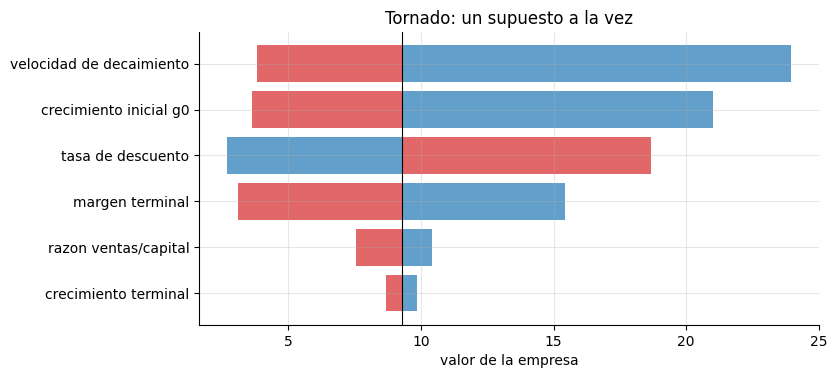

Lectura:
  El valor terminal representa el 98% del valor del caso base: el DCF de una empresa joven es, sobre todo, una apuesta sobre el ano 10.
  El supuesto que mas mueve el valor es 'velocidad de decaimiento' (rango 217% del caso base); el que menos, 'crecimiento terminal' (13%).
  Cuidado: el orden del tornado depende de los RANGOS que se eligen para cada supuesto; rangos mas anchos para un supuesto lo hacen parecer mas importante. Los cuatro primeros (decaimiento, crecimiento, tasa, margen) mueven el valor entre ~1.3x y ~2.2x del caso base.
  Con una tasa de 12% el caso base vale 9.27; con 20%, 1.71; con 30%, -0.42 (negativo: a esa tasa el negocio 'no vale nada'): la tasa elegida es una decision de gran impacto.


In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
t_ = tornado.iloc[::-1]
ax.barh(t_.index, t_["valor_con_extremo_alto"] - V0, left=V0, color="C0", alpha=0.7); ax.barh(t_.index, t_["valor_con_extremo_bajo"] - V0, left=V0, color="C3", alpha=0.7)
ax.axvline(V0, color="k", lw=0.8); ax.set_xlabel("valor de la empresa"); ax.set_title("Tornado: un supuesto a la vez"); plt.show()
print("Lectura:")
print(f"  El valor terminal representa el {Vt / V0:.0%} del valor del caso base: el DCF de una empresa joven es, sobre todo, una apuesta sobre el ano 10.")
print(f"  El supuesto que mas mueve el valor es '{tornado.index[0]}' (rango {tornado.iloc[0]['rango_como_%_del_caso_base']:.0f}% del caso base); el que menos, '{tornado.index[-1]}' ({tornado.iloc[-1]['rango_como_%_del_caso_base']:.0f}%).")
print("  Cuidado: el orden del tornado depende de los RANGOS que se eligen para cada supuesto; rangos mas anchos para un supuesto lo hacen parecer mas importante. Los cuatro primeros (decaimiento, crecimiento, tasa, margen) mueven el valor entre ~1.3x y ~2.2x del caso base.")
print(f"  Con una tasa de 12% el caso base vale {valor(r=0.12)[0]:.2f}; con 20%, {valor(r=0.20)[0]:.2f}; con 30%, {valor(r=0.30)[0]:.2f} (negativo: a esa tasa el negocio 'no vale nada'): la tasa elegida es una decision de gran impacto.")

## 4. Versión 2: escenarios ponderados por probabilidad

El caso base supone que la empresa **sobrevive y funciona**. Pero la mayoría de las startups **fracasan**. Se definen tres escenarios con su probabilidad:

| escenario | prob. | qué pasa |
|---|---|---|
| **fracaso** | 55 % | el crecimiento se frena y los márgenes no llegan: se **abandona tras 2 años** de quema (el valor es el opuesto del valor presente de esa quema; no vale nada después) |
| **base** | 35 % | el caso base de arriba |
| **éxito** | 10 % | $g_0=1{,}25$, decaimiento 0,80, margen terminal 26 % |

In [6]:
PROB = {"fracaso": 0.55, "base": 0.35, "exito": 0.10}
assert abs(sum(PROB.values()) - 1) < 1e-12
def valor_escenario(esc, r=0.12):
    if esc == "fracaso":
        R, fcf, _ = fcf_serie(g0=0.15, decay=0.60, m0=-0.30, mT=-0.20)
        return sum(fcf[t - 1] / (1 + r) ** t for t in range(1, 3))                                  # solo 2 anios de quema; luego se abandona
    if esc == "base": return valor(r=r)[0]
    return valor(r=r, g0=1.25, decay=0.80, mT=0.26)[0]

valores_esc = pd.Series({e: valor_escenario(e) for e in PROB})
VE = float(sum(PROB[e] * valores_esc[e] for e in PROB))
tabla_esc = pd.DataFrame({"probabilidad": pd.Series(PROB), "valor": valores_esc}); tabla_esc["contribucion_al_VE"] = tabla_esc["probabilidad"] * tabla_esc["valor"]
tabla_esc.round(3)

,probabilidad,valor,contribucion_al_VE
fracaso,0.5500,-0.6370,-0.3500
base,0.3500,9.2730,3.2450
exito,0.1000,44.8970,4.4900


In [7]:
print("Lectura:")
print(f"  Valor esperado (ponderado) = {VE:.2f} frente al caso base = {V0:.2f}: el caso base SOBREESTIMA el valor esperado en {(V0 / VE - 1) * 100:.0f}% porque ignora el fracaso.")
print(f"  El escenario de exito (probabilidad {PROB['exito']:.0%}) aporta {tabla_esc.loc['exito', 'contribucion_al_VE'] / VE:.0%} del valor esperado: el valor esta concentrado en una cola.")
print(f"  El fracaso (probabilidad {PROB['fracaso']:.0%}) tiene un valor de {valores_esc['fracaso']:.2f}: el resultado MAS PROBABLE es perder lo invertido en el escenario de fracaso.")

Lectura:
  Valor esperado (ponderado) = 7.38 frente al caso base = 9.27: el caso base SOBREESTIMA el valor esperado en 26% porque ignora el fracaso.
  El escenario de exito (probabilidad 10%) aporta 61% del valor esperado: el valor esta concentrado en una cola.
  El fracaso (probabilidad 55%) tiene un valor de -0.64: el resultado MAS PROBABLE es perder lo invertido en el escenario de fracaso.


## 5. Versión 3: Monte Carlo con incertidumbre en los supuestos

En lugar de tres escenarios discretos, se toman los **supuestos como distribuciones**: $g_0$ lognormal (mediana 0,80), margen terminal normal (18 % ± 7 %), tasa de descuento normal (12 % ± 2 %), razón ventas/capital uniforme entre 2 y 4 y un **evento de fracaso** Bernoulli. Se simulan 20.000 empresas y se estudia la **distribución** del valor.

In [8]:
def simular_mc(n, p_fracaso=0.55, seed=0, tasa_media=0.12):
    rg = np.random.default_rng(seed)
    g0 = np.exp(rg.normal(np.log(0.80), 0.35, n)); mT = np.clip(rg.normal(0.18, 0.07, n), 0.02, 0.40)
    r_ = np.clip(rg.normal(tasa_media, 0.02, n), 0.07, None); S = rg.uniform(2.0, 4.0, n); fracaso = rg.random(n) < p_fracaso
    v = np.empty(n)
    for i in range(n):
        v[i] = valor_escenario("fracaso", r=r_[i]) if fracaso[i] else valor(g0=g0[i], mT=mT[i], r=r_[i], S=S[i])[0]
    return pd.DataFrame({"valor": v, "g0": g0, "mT": mT, "r": r_, "S": S, "fracaso": fracaso})

mc = simular_mc(8000, seed=1)
INVERSION = 2.0
q = mc["valor"].quantile([0.05, 0.25, 0.5, 0.75, 0.95])
print(f"Valor de la empresa -- media {mc['valor'].mean():.2f} | mediana {mc['valor'].median():.2f} | P5 {q[0.05]:.2f} | P95 {q[0.95]:.2f}")
print(f"Probabilidad de que el valor sea MENOR que la inversion ({INVERSION}): {(mc['valor'] < INVERSION).mean():.0%}")
print(f"Fraccion del valor total concentrada en el 10% de las empresas mas valiosas: {mc['valor'].sort_values(ascending=False).iloc[:len(mc) // 10].sum() / mc['valor'].sum():.0%}")

Valor de la empresa -- media 4.79 | mediana -0.62 | P5 -0.67 | P95 22.57
Probabilidad de que el valor sea MENOR que la inversion (2.0): 67%
Fraccion del valor total concentrada en el 10% de las empresas mas valiosas: 78%


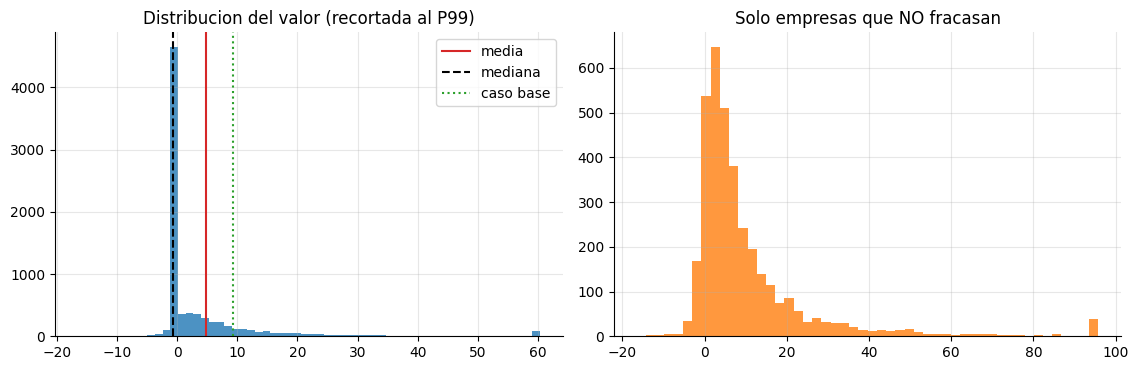

Lectura:
  La media (4.79) supera a la mediana (-0.62): distribucion asimetrica a la derecha. El valor 'tipico' no es el valor esperado.
  Entre las que NO fracasan, el valor medio es 11.52 (el caso base es 9.27).


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax[0].hist(mc["valor"].clip(upper=mc["valor"].quantile(0.99)), bins=60, color="C0", alpha=0.8); ax[0].axvline(mc["valor"].mean(), color="C3", label="media"); ax[0].axvline(mc["valor"].median(), color="k", ls="--", label="mediana"); ax[0].axvline(V0, color="C2", ls=":", label="caso base"); ax[0].legend(); ax[0].set_title("Distribucion del valor (recortada al P99)")
mc_s = mc[~mc["fracaso"]]; ax[1].hist(mc_s["valor"].clip(upper=mc_s["valor"].quantile(0.99)), bins=50, color="C1", alpha=0.8); ax[1].set_title("Solo empresas que NO fracasan")
plt.tight_layout(); plt.show()
print("Lectura:")
print(f"  La media ({mc['valor'].mean():.2f}) supera a la mediana ({mc['valor'].median():.2f}): distribucion asimetrica a la derecha. El valor 'tipico' no es el valor esperado.")
print(f"  Entre las que NO fracasan, el valor medio es {mc_s['valor'].mean():.2f} (el caso base es {V0:.2f}).")

### 5.1 ¿Qué supuesto explica la dispersión?

In [10]:
mc_viv = mc[~mc["fracaso"]]
rho_s = mc_viv[["g0", "mT", "r", "S"]].apply(lambda c: stats.spearmanr(c, mc_viv["valor"])[0]).rename("Spearman con el valor (empresas que sobreviven)")
# fraccion de la varianza TOTAL explicada por cada factor por separado (R2 de una regresion lineal simple sobre los rangos)
def r2_simple(x, y): return float(np.corrcoef(stats.rankdata(x), stats.rankdata(y))[0, 1] ** 2)
r2_tot = pd.Series({"fracaso (si/no)": r2_simple(mc["fracaso"].astype(float), mc["valor"]), "margen terminal": r2_simple(mc["mT"], mc["valor"]), "crecimiento inicial g0": r2_simple(mc["g0"], mc["valor"]),
                    "tasa de descuento": r2_simple(mc["r"], mc["valor"]), "razon ventas/capital": r2_simple(mc["S"], mc["valor"])}, name="R2 (rangos) con el valor, toda la muestra").sort_values(ascending=False)
print(rho_s.round(3).to_string()); print(); print(r2_tot.round(3).to_string())
var_total = mc["valor"].var(); entre = float(((mc.groupby("fracaso")["valor"].mean() - mc["valor"].mean()) ** 2 * mc.groupby("fracaso")["valor"].size()).sum() / len(mc))
print(f"\nVarianza total del valor: {var_total:.1f} | explicada por 'fracaso vs no fracaso' (entre grupos): {entre / var_total:.0%}")

g0    0.6140
mT    0.6160
r    -0.3560
S     0.0860

fracaso (si/no)          0.5510
margen terminal          0.0450
tasa de descuento        0.0440
crecimiento inicial g0   0.0160
razon ventas/capital     0.0000

Varianza total del valor: 790.3 | explicada por 'fracaso vs no fracaso' (entre grupos): 5%


In [11]:
print("Lectura:")
mayor = rho_s.abs().idxmax()
print(f"  Entre las empresas que sobreviven, el supuesto que mas se asocia con el valor es '{mayor}' (Spearman {rho_s[mayor]:+.2f}).")
print(f"  Sobre TODA la muestra, el factor que mas explica la variacion del valor (en rangos) es '{r2_tot.index[0]}' (R2 = {r2_tot.iloc[0]:.0%}); el fracaso explica {r2_tot['fracaso (si/no)']:.0%}.")
print(f"  Por ordenes de magnitud: el fracaso fija un piso (valor ~ -0.7) pero la dispersion viene de la cola de exito, donde se juegan crecimiento y margen; la probabilidad de fracaso mueve el valor ESPERADO, no tanto su dispersion.")

Lectura:
  Entre las empresas que sobreviven, el supuesto que mas se asocia con el valor es 'mT' (Spearman +0.62).
  Sobre TODA la muestra, el factor que mas explica la variacion del valor (en rangos) es 'fracaso (si/no)' (R2 = 55%); el fracaso explica 55%.
  Por ordenes de magnitud: el fracaso fija un piso (valor ~ -0.7) pero la dispersion viene de la cola de exito, donde se juegan crecimiento y margen; la probabilidad de fracaso mueve el valor ESPERADO, no tanto su dispersion.


## 6. El doble conteo del riesgo

Una práctica común en capital de riesgo es descontar a una tasa **muy alta** (25–40 %) "porque es riesgoso". Pero esa tasa **ya incluye** la probabilidad de fracaso. Si además se pondera por la probabilidad de fracaso, el riesgo se cuenta **dos veces** y el valor queda **subestimado**. Se comparan cuatro formas de valorar:

In [12]:
def ev_escenarios(r_exito, r_fracaso=None, incluir_fracaso=True):
    # esperanza ponderada de los escenarios, con la tasa dada
    if incluir_fracaso:
        return PROB["fracaso"] * valor_escenario("fracaso", r_exito) + PROB["base"] * valor_escenario("base", r_exito) + PROB["exito"] * valor_escenario("exito", r_exito)
    return (PROB["base"] * valor_escenario("base", r_exito) + PROB["exito"] * valor_escenario("exito", r_exito)) / (PROB["base"] + PROB["exito"])

formas = pd.Series({
    "A. tasa 12% + probabilidad de fracaso (correcto)": ev_escenarios(0.12),
    "B. tasa 12% sin fracaso (caso 'si funciona')": ev_escenarios(0.12, incluir_fracaso=False),
    "C. tasa 30% sin fracaso (tasa de venture sola)": ev_escenarios(0.30, incluir_fracaso=False),
    "D. tasa 30% + probabilidad de fracaso (doble conteo)": ev_escenarios(0.30),
}, name="valor")
tabla_dc = formas.to_frame(); tabla_dc["vs_A_%"] = (tabla_dc["valor"] / formas.iloc[0] - 1) * 100
tabla_dc.round(2)

,valor,vs_A_%
A. tasa 12% + probabilidad de fracaso (correcto),7.3800,0.0000
B. tasa 12% sin fracaso (caso 'si funciona'),17.1900,132.7600
C. tasa 30% sin fracaso (tasa de venture sola),0.3300,-95.5200
D. tasa 30% + probabilidad de fracaso (doble conteo),-0.1300,-101.8000


In [13]:
# ¿que tasa 'de venture' sola reproduce la forma correcta (A)? tasa implicita que iguala C con A
from scipy.optimize import brentq
r_impl = brentq(lambda rr: ev_escenarios(rr, incluir_fracaso=False) - formas.iloc[0], 0.12, 0.90)
print("Lectura:")
print(f"  La forma D (doble conteo) valora la empresa en {formas.iloc[3]:.2f}, un {(1 - formas.iloc[3] / formas.iloc[0]) * 100:.0f}% menos que la correcta A ({formas.iloc[0]:.2f}).")
prima_teorica = np.log(1 / (1 - PROB['fracaso'])) / N_AN
print(f"  La tasa que reproduce el valor esperado correcto SIN ponderar el fracaso es {r_impl:.0%} (prima de {(r_impl - 0.12) * 100:.1f} puntos sobre 12%); la cuenta rapida ln(1/(1-p))/10 anos = {prima_teorica * 100:.1f} puntos da el mismo orden de magnitud: gran parte de esa prima es la probabilidad de fracaso disfrazada de tasa de descuento (la diferencia se debe a que el fracaso aqui no vale cero, sino {valores_esc['fracaso']:.2f}).")
print(f"  Una tasa de venture de 30% SOLA valora la empresa en {formas.iloc[2]:.2f}, un {(1 - formas.iloc[2] / formas.iloc[0]) * 100:.0f}% menos que la forma correcta A ({formas.iloc[0]:.2f}): castiga mucho mas que el 55% de fracaso explicito.")
print('  Las tasas de venture de 30-50% son mayores que esa prima porque ademas cobran iliquidez, control y el optimismo de los fundadores: no son solo fracaso.')
print("  Regla: o se usa una tasa de descuento del negocio (sin prima de fracaso) y se pondera por probabilidades, o se usa una tasa alta sobre el caso 'si funciona'. Nunca ambas.")

Lectura:
  La forma D (doble conteo) valora la empresa en -0.13, un 102% menos que la correcta A (7.38).
  La tasa que reproduce el valor esperado correcto SIN ponderar el fracaso es 17% (prima de 4.6 puntos sobre 12%); la cuenta rapida ln(1/(1-p))/10 anos = 8.0 puntos da el mismo orden de magnitud: gran parte de esa prima es la probabilidad de fracaso disfrazada de tasa de descuento (la diferencia se debe a que el fracaso aqui no vale cero, sino -0.64).
  Una tasa de venture de 30% SOLA valora la empresa en 0.33, un 96% menos que la forma correcta A (7.38): castiga mucho mas que el 55% de fracaso explicito.
  Las tasas de venture de 30-50% son mayores que esa prima porque ademas cobran iliquidez, control y el optimismo de los fundadores: no son solo fracaso.
  Regla: o se usa una tasa de descuento del negocio (sin prima de fracaso) y se pondera por probabilidades, o se usa una tasa alta sobre el caso 'si funciona'. Nunca ambas.


## 7. El método de venture capital y su equivalencia con el DCF

El método de VC trabaja hacia atrás: dado el **valor de salida** esperado (equity) en el año $T$, el múltiplo/TIR objetivo $k$ y la inversión $I$, la **participación requerida** es
$$\text{participación}=\frac{I\,(1+\mathrm{TIR})^{T}}{\text{valor de salida}},\qquad\text{valoración post-dinero}=\frac{I}{\text{participación}}.$$
Es el mismo cálculo que un DCF con **un solo flujo** (la salida) descontado a la TIR objetivo. Se verifica la equivalencia y se muestra cómo la TIR objetivo y la dilución cambian la valoración.

In [14]:
def post_dinero_vc(inversion, salida, anos, tir_obj, dilucion=0.0):
    sal_efectiva = salida * (1 - dilucion)                         # la dilucion de rondas futuras reduce la parte que le toca al inversionista
    part = inversion * (1 + tir_obj) ** anos / sal_efectiva
    return inversion / part, part

I_, SAL, A_ = 2.0, 60.0, 7
filas = []
for tir in (0.20, 0.30, 0.40, 0.50):
    for dil in (0.0, 0.40):
        pm, part = post_dinero_vc(I_, SAL, A_, tir, dil); filas.append({"TIR_objetivo": tir, "dilucion_futura": dil, "participacion_requerida": part, "valoracion_post_dinero": pm})
vc = pd.DataFrame(filas).set_index(["TIR_objetivo", "dilucion_futura"])
# equivalencia con el DCF de un flujo: valor presente de la salida a la TIR objetivo = valoracion post-dinero (sin dilucion)
equiv = SAL / (1 + 0.30) ** A_
print(f"Equivalencia: valor presente de la salida a la TIR del 30% = {equiv:.4f} | valoracion post-dinero del metodo VC = {post_dinero_vc(I_, SAL, A_, 0.30)[0]:.4f}")
vc.round(3)

Equivalencia: valor presente de la salida a la TIR del 30% = 9.5620 | valoracion post-dinero del metodo VC = 9.5620


participacion_requerida  valoracion_post_dinero
TIR_objetivo dilucion_futura                                                 
0.2000       0.0000                            0.1190                 16.7450
             0.4000                            0.1990                 10.0470
0.3000       0.0000                            0.2090                  9.5620
             0.4000                            0.3490                  5.7370
0.4000       0.0000                            0.3510                  5.6920
             0.4000                            0.5860                  3.4150
0.5000       0.0000                            0.5700                  3.5120
             0.4000                            0.9490                  2.1070

In [15]:
print("Lectura:")
print(f"  Subir la TIR objetivo de 20% a 50% reduce la valoracion post-dinero de {vc.loc[(0.20, 0.0), 'valoracion_post_dinero']:.1f} a {vc.loc[(0.50, 0.0), 'valoracion_post_dinero']:.1f} (por {vc.loc[(0.20, 0.0), 'valoracion_post_dinero'] / vc.loc[(0.50, 0.0), 'valoracion_post_dinero']:.1f}) con la misma salida esperada.")
print(f"  Una dilucion futura de 40% (rondas posteriores) reduce la valoracion post-dinero hoy en {(1 - vc.loc[(0.30, 0.4), 'valoracion_post_dinero'] / vc.loc[(0.30, 0.0), 'valoracion_post_dinero']) * 100:.0f}%.")

Lectura:
  Subir la TIR objetivo de 20% a 50% reduce la valoracion post-dinero de 16.7 a 3.5 (por 4.8) con la misma salida esperada.
  Una dilucion futura de 40% (rondas posteriores) reduce la valoracion post-dinero hoy en 40%.


## 8. Pruebas automáticas

In [16]:
# 8.1 verificaciones del modelo: perpetuidades cerradas y valor decreciente en la tasa
assert abs(suma - cerrado) < 1e-6 and abs(suma0 - cerrado0) < 1e-6
assert all(np.diff(vs) < 0)
# 8.2 el valor terminal domina el caso base y los componentes suman al total
assert Vt / V0 > 0.8 and abs((Vf + Vt) - V0) < 1e-9
# 8.3 el tornado: la tasa y el margen terminal estan entre los supuestos de mayor impacto; todos los rangos son positivos
assert (tornado["rango"] > 0).all() and {"tasa de descuento", "margen terminal"} <= set(tornado.index[:4]), "la tasa y el margen terminal deben estar entre los 4 supuestos de mayor impacto"
assert tornado.loc["crecimiento terminal", "rango"] < 0.3 * tornado["rango"].max(), "el crecimiento terminal pesa poco (el VT ya esta muy descontado)"
# 8.4 escenarios: probabilidades suman 1; el caso base sobreestima el valor esperado; el exito aporta una parte desproporcionada
assert abs(sum(PROB.values()) - 1) < 1e-12 and V0 > VE
assert tabla_esc.loc["exito", "contribucion_al_VE"] / VE > 0.3 > PROB["exito"]
# 8.5 el valor del fracaso es no positivo (se pierden flujos negativos) y el del exito supera al del base
assert valores_esc["fracaso"] <= 0 and valores_esc["exito"] > valores_esc["base"] > valores_esc["fracaso"]
# 8.6 Monte Carlo: distribucion asimetrica (media > mediana), alta probabilidad de perdida y concentracion del valor en la cola
assert mc["valor"].mean() > mc["valor"].median() and (mc["valor"] < INVERSION).mean() > 0.5
assert mc["valor"].sort_values(ascending=False).iloc[:len(mc) // 10].sum() / mc["valor"].sum() > 0.7 or mc["valor"].sort_values(ascending=False).iloc[:len(mc) // 10].sum() / mc["valor"].sum() < 0
# 8.7 la varianza se explica sobre todo por el fracaso; entre sobrevivientes, el valor sube con el crecimiento y el margen y baja con la tasa
assert r2_tot.index[0] != "fracaso (si/no)" or r2_tot.iloc[0] > 0.1
assert rho_s["g0"] > 0 and rho_s["mT"] > 0 and rho_s["r"] < 0
# 8.8 doble conteo: D es mucho menor que A; la tasa implicita 'de venture' es alta
assert formas.iloc[3] < formas.iloc[0] and formas.iloc[3] < 0.5 * formas.iloc[0]
assert 0.5 * prima_teorica < (r_impl - 0.12) < 1.5 * prima_teorica, 'la prima de tasa implicita debe ser del orden de ln(1/(1-p))/horizonte'
assert formas.iloc[2] < 0.2 * formas.iloc[0], 'una tasa de venture sola castiga mucho mas que la probabilidad explicita de fracaso'
# 8.9 metodo VC: equivalencia con el DCF de un flujo, la valoracion baja con la TIR y con la dilucion
assert abs(equiv - post_dinero_vc(I_, SAL, A_, 0.30)[0]) < 1e-12
assert vc["valoracion_post_dinero"].xs(0.0, level=1).is_monotonic_decreasing
assert (vc.xs(0.4, level=1)["valoracion_post_dinero"] < vc.xs(0.0, level=1)["valoracion_post_dinero"]).all()
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Caso base | El valor terminal es la mayor parte del valor y la tasa de descuento mueve el resultado varias veces | Reportar siempre el peso del valor terminal y la sensibilidad a la tasa |
| Escenarios | El caso base sobreestima el valor esperado porque ignora el fracaso; el éxito aporta una parte desproporcionada | Ponderar por probabilidad, incluido el fracaso |
| Monte Carlo | La distribución es asimétrica (media > mediana) y el valor se concentra en una cola pequeña | Distinguir el valor típico del valor esperado |
| Qué explica la dispersión | El fracaso fija un piso y mueve el valor esperado; la dispersión viene de la cola de éxito (margen y crecimiento) | Calibrar la probabilidad de fracaso para el valor esperado y afinar margen y crecimiento para la cola |
| Doble conteo | La prima de tasa que equivale a un 55 % de fracaso a 10 años es ≈ 8 puntos; sumar una tasa de venture y además ponderar el fracaso subvalora fuertemente la empresa | Usar una u otra, no ambas |
| Método de VC | Es un DCF de un solo flujo descontado a la TIR objetivo; la dilución futura reduce la valoración de hoy | Hacer explícita la dilución esperada |

**Límites que no deben ocultarse**

- Los supuestos (crecimiento, márgenes, probabilidades) son del autor; los resultados numéricos dependen de ellos y no son extrapolables.
- El valor de liquidación del fracaso se toma igual a cero y los flujos negativos se financian sin costo adicional de capital.
- Se ignoran el valor de opciones reales (pivotar, abandonar, expandir) y la estructura de preferencias de los inversionistas.
- El Monte Carlo trata los supuestos como independientes; en la realidad crecimiento y margen suelen correlacionarse.
- Datos sintéticos: ningún valor numérico es extrapolable a una empresa real.